# **Human Face Emotion Detection Using AI**  

**Authors:** Cindy Chen, Maria Guasch, Núria Moll
  
**Degree:** Biomedical Engineering

**Subject:** Artificial Intelligence in Biomedical Engineering

**Course:** 2023-2024

---

### **1. INTRODUCTION**

Sometimes, more importance is given to what is said with the voice than what is said with the facial expression. However, it is easier to lie or to hide emotions with the voice. After all, emotions appear unexpectedly and in an automatic way, and they can be reflected through our facial expressions.  

The ability to recognize and understand emotions is essential in our daily interactions. However, facial expressions can be complex and subtle, making interpreting emotions through them difficult even for humans. In this context, Artificial Intelligence (AI) can be used as a tool for detecting and classifying emotions in images, offering precision and objectivity that can be especially useful in clinical and therapeutic environments.

---

### **2. OBJECTIVES**

The objective of this project is to develop an algorithm capable of classifying people's emotions based on their faces, through an image, or by detecting the face with a webcam. 

This algorithm could be useful in several scenarios [[1]](https://www.morphcast.com/blog/face-emotion-recognition-in-healthcare-how-can-it-be-used/):  

1. **Patient communication**. Face emotion recognition can be used to assist healthcare providers in identifying and interpreting the emotional state of their patients. This is particularly useful for those patients who have difficulties communicating verbally. For example: autistic patients, pediatric patients, deaf/mute patients, patients who have suffered an accident/trauma.

2. **Disease diagnosis and monitoring**. Some diseases and conditions (for example depression and anxiety) can manifest in changes in facial expressions and body language.

3. **Customer service**. This algorithm can also be used to enhance the customer experience in healthcare settings.

In terms of the algorithm itself, it consists of images as inputs and the classification and probabilities of a specific emotion as the output.

##### **2.1 How can this model be implemented in consultations?**  

The ultimate goal is to implement the algorithm into a webcam. This way psychological/psychiatric consultations would be able to detect the facial expressions of the patient in real time. Obviously, it's not useful or necessary in all cases. But let's consider the example of an autistic patient entering the consultation. As it is known, autistic individuals face challenges in identifying and expressing emotions, which can contribute to mental health problems like anxiety and depression. Implementing cameras connected to this facial recognition algorithm can help address this difficulty by providing an objective way to detect the patient's emotions. This could allow therapists to better adjust their approaches, providing more effective support and thereby improving the mental health and quality of life of autistic individuals. The same applies to pediatric patients or those who, due to trauma, may struggle to express their emotions easily.


---

### **3. DATASET**  

##### **3.1 Prepare the environment**

Import the different modules used for the project.

In [ ]:
# Import modules
import pandas as pd
import numpy as np
import os
import cv2
import seaborn as sns
import matplotlib.pyplot as plt
import tensorflow as tf

%matplotlib inline

##### **3.2 Human Facial Expression Dataset**

The dataset used for the development of this project was obtained from Kaggle [[2]](https://www.kaggle.com/code/ramubathula/mini-project/input). This particular dataset consisted of a series of images divided into folders based on the different facial expressions:
- Angry
- Disgust
- Fear
- Happy
- Neutral
- Sad
- Surprise

Additionally, the images from the dataset were already labeled and divided into a train and test set.


In [26]:
# Data location
train_path = "C:/Users/cindy/Desktop/data/train/"
test_path = "C:/Users/cindy/Desktop/data/test/"

In [ ]:
# Define function to load the dataset
def load_dataset(data_path):
    """Function to load a dataset from a path"""

    image_paths = []  # List to store all image paths
    labels = []  # List to store their corresponding labels

    # Iterate over each folder (label) in the data_path
    for label in os.listdir(data_path):
        # Iterate over each file (image) in the folder
        for filename in os.listdir(data_path + label):
            # Obtain the full path for each image
            image_path = os.path.join(data_path, label, filename)
            # Append them to the empty list created before
            image_paths.append(image_path)
            labels.append(label)

    return image_paths, labels

In [ ]:
# Convert the train data into a dataframe
train = pd.DataFrame()
train["image_path"], train["label"] = load_dataset(train_path)

# Shuffle the rows of the train dataset
train = train.sample(frac=1).reset_index(drop=True)

# Display train dataframe
train.head()

,image_path,label
0,C:/Users/cindy/Desktop/data/train/happy\Traini...,happy
1,C:/Users/cindy/Desktop/data/train/surprise\Tra...,surprise
2,C:/Users/cindy/Desktop/data/train/fear\Trainin...,fear
3,C:/Users/cindy/Desktop/data/train/fear\Trainin...,fear
4,C:/Users/cindy/Desktop/data/train/sad\Training...,sad


In [27]:
# Convert the test data into a dataframe
test = pd.DataFrame()
test["image_path"], test["label"] = load_dataset(test_path)

# Display test dataframe
test.head()

,image_path,label
0,C:/Users/cindy/Desktop/data/test/angry\Private...,angry
1,C:/Users/cindy/Desktop/data/test/angry\Private...,angry
2,C:/Users/cindy/Desktop/data/test/angry\Private...,angry
3,C:/Users/cindy/Desktop/data/test/angry\Private...,angry
4,C:/Users/cindy/Desktop/data/test/angry\Private...,angry


---

### **4. EXPLORATORY DATA ANALYSIS**  

Firtly, we did a simple exploratory data analysis (EDA) to get a general idea of the dataset and understand its characteristics.  

- **Distribution of emotions across the dataset:**

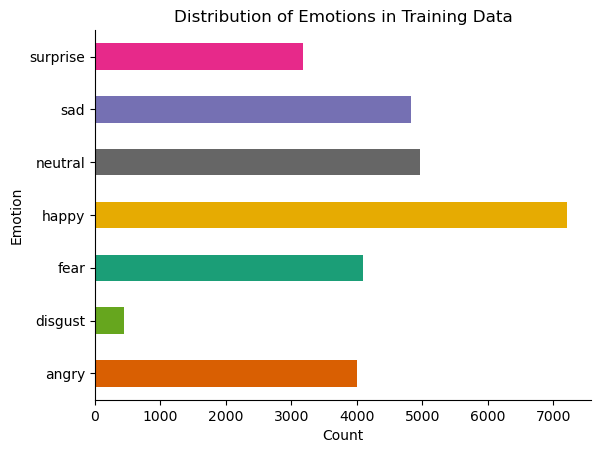

In [ ]:
# Distribution of emotions in training data
colors = ["#D95F02", "#66A61E", "#1B9E77", "#E6AB02", "#666666", "#7570B3", "#E7298A"]
train.groupby("label").size().plot(kind="barh", color=colors)
plt.gca().spines[
    [
        "top",
        "right",
    ]
].set_visible(False)

plt.title("Distribution of Emotions in Training Data")
plt.xlabel("Count")
plt.ylabel("Emotion")
plt.show()

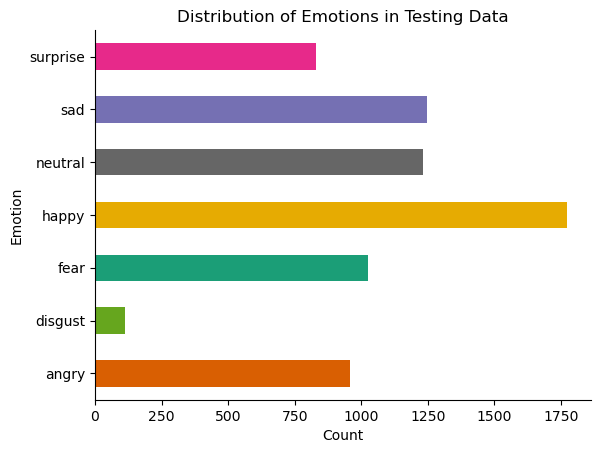

In [ ]:
# Distribution of emotions in testing data
colors = ["#D95F02", "#66A61E", "#1B9E77", "#E6AB02", "#666666", "#7570B3", "#E7298A"]
test.groupby("label").size().plot(kind="barh", color=colors)
plt.gca().spines[
    [
        "top",
        "right",
    ]
].set_visible(False)

plt.title("Distribution of Emotions in Testing Data")
plt.xlabel("Count")
plt.ylabel("Emotion")
plt.show()

As we can see, the dataset is quite balanced for each emotion, except for the *disgust* one. This could lead to problems like bias, misclassification, etc.

- **Visualize sample images:**

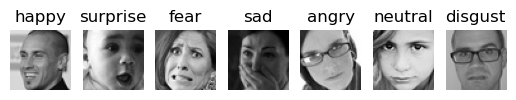

In [8]:
# Select 1 image for each emotion from the training dataset
sample_images = []
for emotion in train["label"].unique():
    sample_images.append(train[train["label"] == emotion].sample(1))

# Concatenate the samples
sample_images = pd.concat(sample_images)

# Read and display the images
for i, (index, row) in enumerate(sample_images.iterrows()):
    img = cv2.imread(row["image_path"])

    # Convert them from BGR (OpenCV) to RGB (Matplotlib)
    img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

    plt.subplot(1, 7, i + 1)
    plt.imshow(img)
    plt.title(row["label"])
    plt.axis("off")

plt.show()

---

### **5. DATA PREPROCESSING**  

In this section, the images were loaded using the ``load_img`` function and converted to grayscale using the ``color_mode`` function and then reshaped to the same size. 

In [9]:
# Import modules
from tqdm.notebook import tqdm
from keras.preprocessing.image import load_img
from sklearn.preprocessing import LabelEncoder
from tensorflow.keras.utils import to_categorical

In [ ]:
# Define function to load the images
def load_images(image_paths):
    """Function that loads the images, converts them
    to grayscale and reshapes them to the same size."""

    values = []  # List to store the values

    # Load images and convert them to grayscale
    for image in tqdm(image_paths):
        img = load_img(image, color_mode="grayscale")
        img = np.array(img)

        # Fill values list with images
        values.append(img)

    # Convert list of images to array and reshape
    values = np.array(values)
    values = values.reshape(len(values), 48, 48, 1)

    return values

In [11]:
# Feature extraction for the training images
train_values = load_images(train["image_path"])

  0%|          | 0/28709 [00:00<?, ?it/s]

In [12]:
# Feature extraction for the testing images
test_values = load_images(test["image_path"])

  0%|          | 0/7178 [00:00<?, ?it/s]

In [ ]:
# Normalize the pixel values of the images
x_train = train_values / 255.0
x_test = test_values / 255.0

# Convert label strings to integer labels
label_encoder = LabelEncoder()
label_encoder.fit(train["label"])
y_train = label_encoder.transform(train["label"])
y_test = label_encoder.transform(test["label"])

# Convert integer labels into one-hot encoded vectors
y_train = to_categorical(y_train, num_classes=7)
y_test = to_categorical(y_test, num_classes=7)

---

### **6. KERAS MODEL**  

The next step was to design our model. In our case, Convolutional Neural Networks (CNN) have been used, which are particularly useful for image-related tasks as they are very effective in image classification and segmentation, among other applications.

In [ ]:
from keras.models import Sequential
from keras.layers import (
    BatchNormalization,
    Conv2D,
    Dense,
    Dropout,
    Flatten,
    MaxPooling2D,
)

##### **6.1 Define Keras Model**

We will use the Sequential model from Keras that allows controlling the characteristics of each layer. This model indicates a linear stacking of layers, where the output of one layer becomes the input of the next.

First, we set the input_shape argument to (48, 48, 1) as the input images have a resolution of 48x48 pixels. And since the images are in grayscale, there's only one channel representing the intensity of each pixel.

This first model was inspired by one we found on Kaggle [[3]](https://www.kaggle.com/code/juniorbueno/opencv-classification-of-emotions/notebook).  The layers of the model are:  
- **Convolutional layers:** with 64, 128 and 256 filters in the three blocks and a filter size of 3x3 meaning each filter considers a 3x3 pixel neighborhood. The ReLu activation function was used which introduces non-linearity to the network and helps the model learn complex patterns in the data.
- **Batch Normalization:** to normalize activations from the previous layer.
- **Max Pooling:** to reduce spatial dimensions and increase speed.
- **Dropout:** to randomly drop a percentage of activations to prevent overfitting.
- **Flatten:** to transform the multi-dimensional output of the convolutional layers into a single-dimensional vector.
- **Dense**

In [ ]:
# Sequential Keras Model
model = Sequential()

# Input shape of the images
input_shape = (48, 48, 1)

# Layers
model.add(
    Conv2D(64, (3, 3), input_shape=input_shape, activation="relu", padding="same")
)
model.add(BatchNormalization())
model.add(MaxPooling2D(pool_size=(2, 2)))
model.add(Dropout(0.2))

model.add(Conv2D(128, (3, 3), activation="relu", padding="same"))
model.add(Conv2D(128, (3, 3), activation="relu", padding="same"))
model.add(BatchNormalization())
model.add(MaxPooling2D(pool_size=(2, 2)))
model.add(Dropout(0.2))

model.add(Conv2D(256, (3, 3), activation="relu", padding="same"))
model.add(Conv2D(256, (3, 3), activation="relu", padding="same"))
model.add(BatchNormalization())
model.add(MaxPooling2D(pool_size=(2, 2)))
model.add(Dropout(0.2))

model.add(Flatten())
model.add(Dense(128, activation="relu"))
model.add(BatchNormalization())
model.add(Dropout(0.2))

# Output layer with softmax function to normalize the output to a probability distribution
model.add(Dense(7, activation="softmax"))

C:\Users\cindy\AppData\Roaming\Python\Python39\site-packages\keras\src\layers\convolutional\base_conv.py:107: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


##### **6.2 Compile Keras Model**

To compile the model, the loss function used to evaluate each set of weights was the *categorical crossentropy* because it's suitable for multi-class classification problems like ours.  

For the optimizer used to search through different weights of a network, a stochastic gradient descent algorithm called *adam* was used.     

Finally, because it is a classification problem, the *accuracy* was also collected.

In [ ]:
# Compile the Keras Model
model.compile(loss="categorical_crossentropy", optimizer="adam", metrics=["accuracy"])

model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 48, 48, 64)     │           640 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 48, 48, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 24, 24, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 24, 24, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 24, 24, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 24, 24, 128)    │       147,584 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 24, 24, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 12, 12, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 12, 12, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 12, 12, 256)    │       295,168 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 12, 12, 256)    │       590,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 12, 12, 256)    │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 6, 6, 256)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 6, 6, 256)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 9216)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │     1,179,776 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 128)            │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 7)              │           903 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,290,311 (8.74 MB)

 Trainable params: 2,289,159 (8.73 MB)

 Non-trainable params: 1,152 (4.50 KB)

##### **6.3 Fit the Keras Model**

After the creation of the model, it was time to fit the model using the training dataset. In our case, the fixed number of iterations in the training process (epochs) was set to 20. And the number of dataset rows that are considered before the model weights are updated (batch_size) within each epoch was set to 64.

In [ ]:
# Fit the Keras Model
history = model.fit(
    x=x_train,
    y=y_train,
    batch_size=64,
    epochs=20,
    verbose=1,
    validation_data=(x_test, y_test),
)

Epoch 1/20
449/449 ━━━━━━━━━━━━━━━━━━━━ 358s 789ms/step - accuracy: 0.2732 - loss: 1.9904 - val_accuracy: 0.1860 - val_loss: 2.2171
Epoch 2/20
449/449 ━━━━━━━━━━━━━━━━━━━━ 345s 769ms/step - accuracy: 0.4599 - loss: 1.4194 - val_accuracy: 0.4960 - val_loss: 1.3039
Epoch 3/20
449/449 ━━━━━━━━━━━━━━━━━━━━ 346s 770ms/step - accuracy: 0.5332 - loss: 1.2363 - val_accuracy: 0.5173 - val_loss: 1.2913
Epoch 4/20
449/449 ━━━━━━━━━━━━━━━━━━━━ 345s 769ms/step - accuracy: 0.5797 - loss: 1.1192 - val_accuracy: 0.5660 - val_loss: 1.1442
Epoch 5/20
449/449 ━━━━━━━━━━━━━━━━━━━━ 345s 769ms/step - accuracy: 0.6148 - loss: 1.0224 - val_accuracy: 0.5566 - val_loss: 1.1887
Epoch 6/20
449/449 ━━━━━━━━━━━━━━━━━━━━ 345s 768ms/step - accuracy: 0.6456 - loss: 0.9573 - val_accuracy: 0.6011 - val_loss: 1.0856
Epoch 7/20
449/449 ━━━━━━━━━━━━━━━━━━━━ 345s 768ms/step - accuracy: 0.6807 - loss: 0.8749 - val_accuracy: 0.5619 - val_loss: 1.1806
Epoch 8/20
449/449 ━━━━━━━━━━━━━━━━━━━━ 345s 767ms/step - accuracy: 0.7061 -

- **Learning curves using the history variable.**

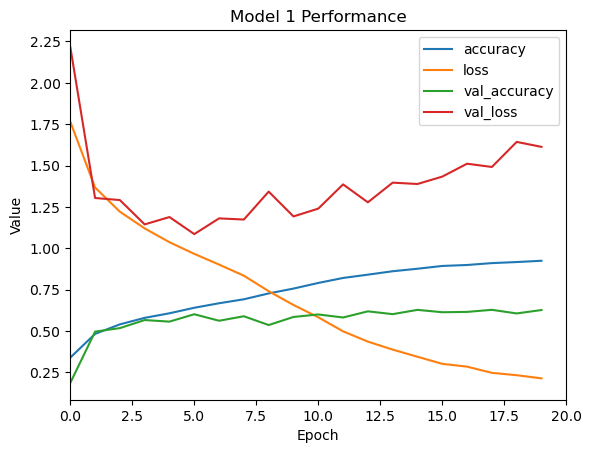

In [18]:
# Model performance plot
perf_1 = pd.DataFrame(history.history)
perf_1.plot()
plt.xlim(0, 20)
plt.title("Model 1 Performance")
plt.xlabel("Epoch")
plt.ylabel("Value")
plt.show()

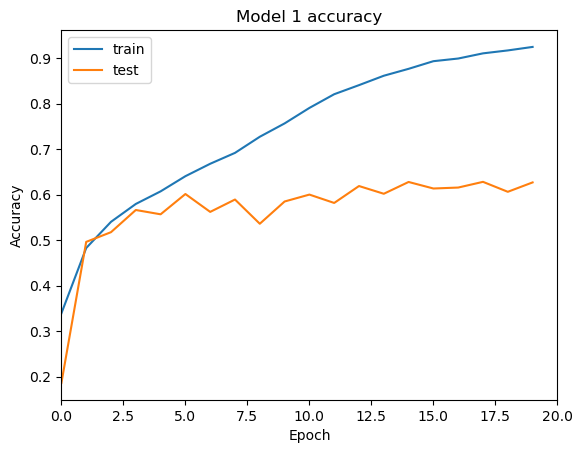

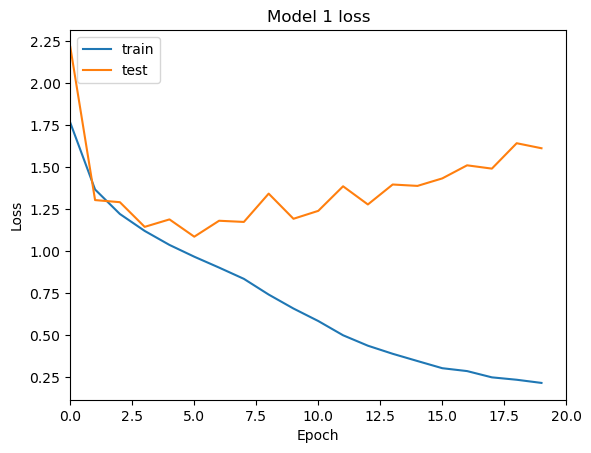

In [ ]:
# Summarize history for accuracy
plt.plot(history.history["accuracy"])
plt.plot(history.history["val_accuracy"])
plt.xlim(0, 20)
plt.title("Model 1 accuracy")
plt.ylabel("Accuracy")
plt.xlabel("Epoch")
plt.legend(["train", "test"], loc="upper left")
plt.show()

# Summarize history for loss
plt.plot(history.history["loss"])
plt.plot(history.history["val_loss"])
plt.xlim(0, 20)
plt.title("Model 1 loss")
plt.ylabel("Loss")
plt.xlabel("Epoch")
plt.legend(["train", "test"], loc="upper left")
plt.show()

In [ ]:
# Evaluate the model 1
loss, accuracy = model.evaluate(x_train, y_train)
print("Accuracy of Model 1: %.2f" % (accuracy * 100))
print("Loss of Model 1: %.2f" % (loss * 100))

val_loss, val_accuracy = model.evaluate(x_test, y_test)
print("Validation accuracy of Model 1: %.2f" % (val_accuracy * 100))
print("Validation loss of Model 1: %.2f" % (val_loss * 100))

898/898 ━━━━━━━━━━━━━━━━━━━━ 82s 91ms/step - accuracy: 0.9865 - loss: 0.0541
Accuracy of Model 1: 98.48
Loss of Model 1: 5.72
225/225 ━━━━━━━━━━━━━━━━━━━━ 18s 80ms/step - accuracy: 0.6085 - loss: 1.6875
Validation accuracy of Model 1: 62.66
Validation loss of Model 1: 161.30


In [ ]:
train_score = model.evaluate(X_train, train_y, verbose=0)
print("Train loss:", train_score[0])
print("Train accuracy:", 100 * train_score[1])
test_score = model.evaluate(X_test, test_y, verbose=0)
print("Test loss:", test_score[0])
print("Test accuracy:", 100 * test_score[1])

In the end, the model obtained has achieved a final accuracy of 0.9299. This indicates the accuracy of the trained data. However, if we analyze the val_accuracy, which refers to how well the model works in general for cases outside the training set, the value obtained was 0.6266.   

Overall, we can see that the first model is performing well and learning from the training data. However, the validation loss seems to decrease but then starts to increase again. This could indicate that the model is starting to overfit to the training data. 

---

### **7. ACTIVATION FUNCTIONS**

Now, we are going to modify the activation function to see if it gives us a higher accuracy and a lower loss. The first model used the ReLu (Rectified Linear Unit) activation function, which is one of the most popular activation functions used in neural networks. This function is defined as:  

$$ f(x) = \max(0, x) $$  

Which means it returns 0 for negative inputs and the input value for positive inputs.  

Now we will try with different activation functions.

- **ELU (Exponential Linear Unit):** it is defined as:  

$$ 
f(x) = 
\begin{cases}
x & \text{if } x > 0 \\
\alpha \cdot (\exp(x) - 1) & \text{if } x \leq 0
\end{cases}
$$

Where $\alpha$ is a hyperparameter that controls the output of negative values when $x \leq 0$

In [ ]:
# Sequential Keras Model
model_2 = Sequential()

# Input shape of the images
input_shape = (48, 48, 1)

# Layers
model_2.add(
    Conv2D(64, (3, 3), input_shape=input_shape, activation="elu", padding="same")
)
model_2.add(BatchNormalization())
model_2.add(MaxPooling2D(pool_size=(2, 2)))
model_2.add(Dropout(0.2))

model_2.add(Conv2D(128, (3, 3), activation="elu", padding="same"))
model_2.add(Conv2D(128, (3, 3), activation="elu", padding="same"))
model_2.add(BatchNormalization())
model_2.add(MaxPooling2D(pool_size=(2, 2)))
model_2.add(Dropout(0.2))

model_2.add(Conv2D(256, (3, 3), activation="elu", padding="same"))
model_2.add(Conv2D(256, (3, 3), activation="elu", padding="same"))
model_2.add(BatchNormalization())
model_2.add(MaxPooling2D(pool_size=(2, 2)))
model_2.add(Dropout(0.2))

model_2.add(Flatten())
model_2.add(Dense(128, activation="elu"))
model_2.add(BatchNormalization())
model_2.add(Dropout(0.2))

# Output layer with softmax function to normalize the output to a probability distribution
model_2.add(Dense(7, activation="softmax"))

# Compile the Keras Model
model_2.compile(loss="categorical_crossentropy", optimizer="adam", metrics=["accuracy"])

In [ ]:
# Fit the Keras Model
history_2 = model_2.fit(
    x=x_train,
    y=y_train,
    batch_size=64,
    epochs=20,
    verbose=1,
    validation_data=(x_test, y_test),
)

Epoch 1/20
449/449 ━━━━━━━━━━━━━━━━━━━━ 356s 785ms/step - accuracy: 0.3007 - loss: 1.9467 - val_accuracy: 0.3876 - val_loss: 1.5834
Epoch 2/20
449/449 ━━━━━━━━━━━━━━━━━━━━ 350s 780ms/step - accuracy: 0.4847 - loss: 1.3630 - val_accuracy: 0.5061 - val_loss: 1.3263
Epoch 3/20
449/449 ━━━━━━━━━━━━━━━━━━━━ 350s 779ms/step - accuracy: 0.5638 - loss: 1.1622 - val_accuracy: 0.4567 - val_loss: 1.4286
Epoch 4/20
449/449 ━━━━━━━━━━━━━━━━━━━━ 350s 780ms/step - accuracy: 0.6120 - loss: 1.0392 - val_accuracy: 0.5556 - val_loss: 1.1644
Epoch 5/20
449/449 ━━━━━━━━━━━━━━━━━━━━ 350s 779ms/step - accuracy: 0.6463 - loss: 0.9505 - val_accuracy: 0.4791 - val_loss: 1.4671
Epoch 6/20
449/449 ━━━━━━━━━━━━━━━━━━━━ 349s 778ms/step - accuracy: 0.6872 - loss: 0.8414 - val_accuracy: 0.5660 - val_loss: 1.2453
Epoch 7/20
449/449 ━━━━━━━━━━━━━━━━━━━━ 349s 777ms/step - accuracy: 0.7345 - loss: 0.7273 - val_accuracy: 0.5801 - val_loss: 1.2412
Epoch 8/20
449/449 ━━━━━━━━━━━━━━━━━━━━ 349s 777ms/step - accuracy: 0.7693 -

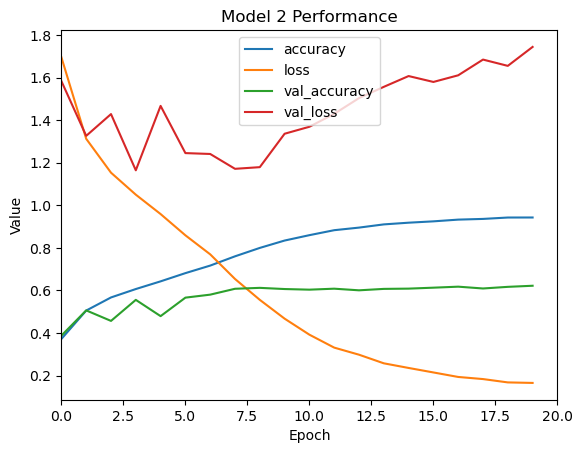

In [23]:
# Model performance plot
perf_2 = pd.DataFrame(history_2.history)
perf_2.plot()
plt.xlim(0, 20)
plt.title("Model 2 Performance")
plt.xlabel("Epoch")
plt.ylabel("Value")
plt.show()

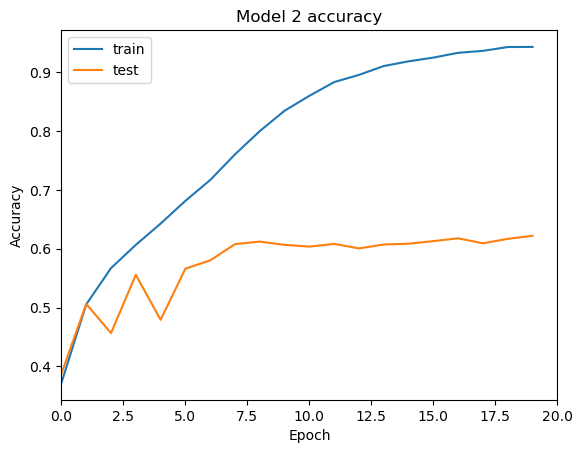

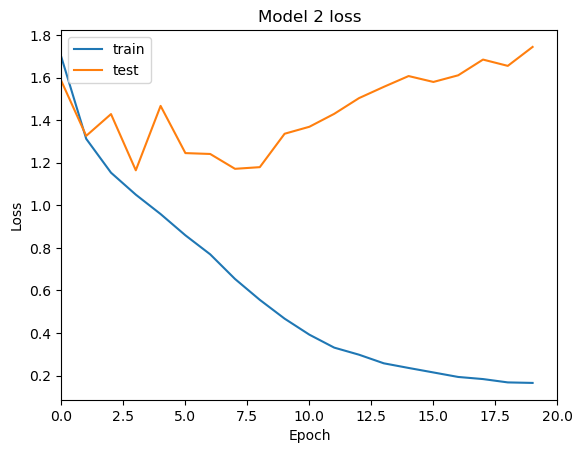

In [ ]:
# Summarize history for accuracy
plt.plot(history_2.history["accuracy"])
plt.plot(history_2.history["val_accuracy"])
plt.xlim(0, 20)
plt.title("Model 2 accuracy")
plt.ylabel("Accuracy")
plt.xlabel("Epoch")
plt.legend(["train", "test"], loc="upper left")
plt.show()

# Summarize history for loss
plt.plot(history_2.history["loss"])
plt.plot(history_2.history["val_loss"])
plt.xlim(0, 20)
plt.title("Model 2 loss")
plt.ylabel("Loss")
plt.xlabel("Epoch")
plt.legend(["train", "test"], loc="upper left")
plt.show()

In [ ]:
# Evaluate the model 2
loss, accuracy = model_2.evaluate(x_train, y_train)
print("Accuracy of Model 2: %.2f" % (accuracy * 100))
print("Loss of Model 2: %.2f" % (loss * 100))

val_loss, val_accuracy = model_2.evaluate(x_test, y_test)
print("Validation accuracy of Model 2: %.2f" % (val_accuracy * 100))
print("Validation loss of Model 2: %.2f" % (val_loss * 100))

898/898 ━━━━━━━━━━━━━━━━━━━━ 81s 90ms/step - accuracy: 0.9850 - loss: 0.0535
Accuracy of Model 2: 98.43
Loss of Model 2: 5.50
225/225 ━━━━━━━━━━━━━━━━━━━━ 19s 86ms/step - accuracy: 0.5910 - loss: 1.8556
Validation accuracy of Model 2: 62.19
Validation loss of Model 2: 174.42


- **SELU (Scaled Exponential Linear Unit):** it is defined as:

$$ 
f(x) = \lambda 
\begin{cases}
x & \text{if } x > 0 \\
\alpha \cdot (\exp(x) - 1) & \text{if } x \leq 0
\end{cases}
$$ 

Where $\lambda$ and $\alpha$ are hyperparameters derived from the distribution of weights and biases of the network.

In [ ]:
# Sequential Keras Model
model_3 = Sequential()

# Input shape of the images
input_shape = (48, 48, 1)

# Layers
model_3.add(
    Conv2D(64, (3, 3), input_shape=input_shape, activation="selu", padding="same")
)
model_3.add(BatchNormalization())
model_3.add(MaxPooling2D(pool_size=(2, 2)))
model_3.add(Dropout(0.2))

model_3.add(Conv2D(128, (3, 3), activation="selu", padding="same"))
model_3.add(Conv2D(128, (3, 3), activation="selu", padding="same"))
model_3.add(BatchNormalization())
model_3.add(MaxPooling2D(pool_size=(2, 2)))
model_3.add(Dropout(0.2))

model_3.add(Conv2D(256, (3, 3), activation="selu", padding="same"))
model_3.add(Conv2D(256, (3, 3), activation="selu", padding="same"))
model_3.add(BatchNormalization())
model_3.add(MaxPooling2D(pool_size=(2, 2)))
model_3.add(Dropout(0.2))

model_3.add(Flatten())
model_3.add(Dense(128, activation="selu"))
model_3.add(BatchNormalization())
model_3.add(Dropout(0.2))

# Output layer with softmax function to normalize the output to a probability distribution
model_3.add(Dense(7, activation="softmax"))

# Compile the Keras Model
model_3.compile(loss="categorical_crossentropy", optimizer="adam", metrics=["accuracy"])

In [ ]:
# Fit the Keras Model
history_3 = model_3.fit(
    x=x_train,
    y=y_train,
    batch_size=64,
    epochs=20,
    verbose=1,
    validation_data=(x_test, y_test),
)

Epoch 1/20
449/449 ━━━━━━━━━━━━━━━━━━━━ 347s 765ms/step - accuracy: 0.3102 - loss: 1.9244 - val_accuracy: 0.4452 - val_loss: 1.4537
Epoch 2/20
449/449 ━━━━━━━━━━━━━━━━━━━━ 345s 768ms/step - accuracy: 0.4863 - loss: 1.3554 - val_accuracy: 0.3803 - val_loss: 1.5664
Epoch 3/20
449/449 ━━━━━━━━━━━━━━━━━━━━ 344s 766ms/step - accuracy: 0.5541 - loss: 1.1764 - val_accuracy: 0.5437 - val_loss: 1.2142
Epoch 4/20
449/449 ━━━━━━━━━━━━━━━━━━━━ 344s 765ms/step - accuracy: 0.5964 - loss: 1.0684 - val_accuracy: 0.3678 - val_loss: 1.7604
Epoch 5/20
449/449 ━━━━━━━━━━━━━━━━━━━━ 343s 764ms/step - accuracy: 0.6298 - loss: 0.9838 - val_accuracy: 0.5634 - val_loss: 1.2999
Epoch 6/20
449/449 ━━━━━━━━━━━━━━━━━━━━ 344s 765ms/step - accuracy: 0.6724 - loss: 0.8879 - val_accuracy: 0.5758 - val_loss: 1.1235
Epoch 7/20
449/449 ━━━━━━━━━━━━━━━━━━━━ 343s 765ms/step - accuracy: 0.7073 - loss: 0.7919 - val_accuracy: 0.5779 - val_loss: 1.1657
Epoch 8/20
449/449 ━━━━━━━━━━━━━━━━━━━━ 343s 765ms/step - accuracy: 0.7429 -

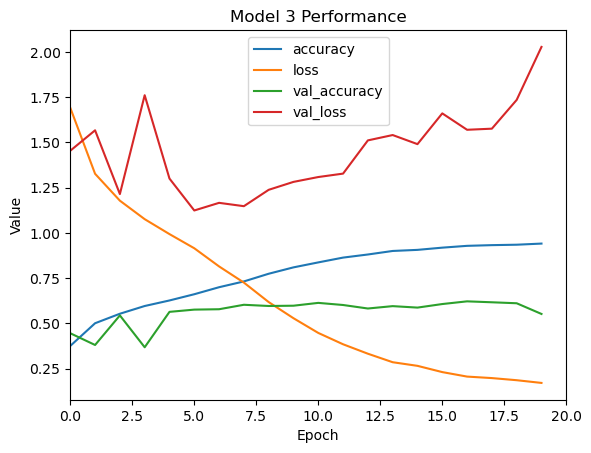

In [28]:
# Model performance plot
perf_3 = pd.DataFrame(history_3.history)
perf_3.plot()
plt.xlim(0, 20)
plt.title("Model 3 Performance")
plt.xlabel("Epoch")
plt.ylabel("Value")
plt.show()

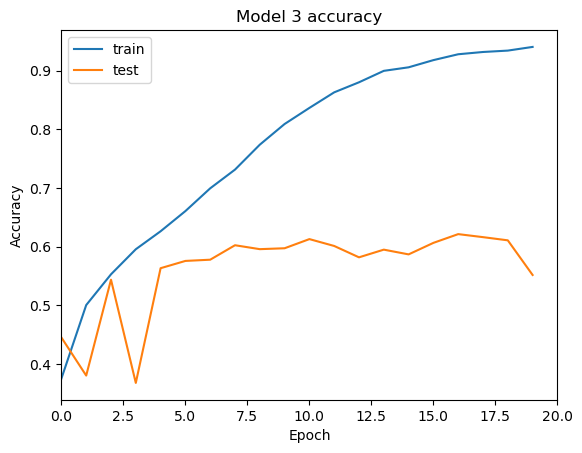

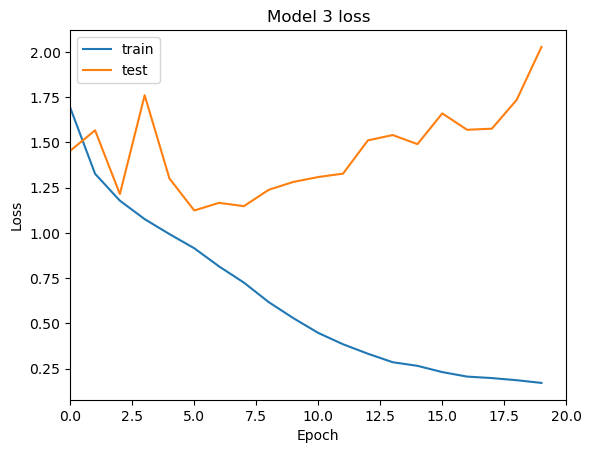

In [ ]:
# Summarize history for accuracy
plt.plot(history_3.history["accuracy"])
plt.plot(history_3.history["val_accuracy"])
plt.xlim(0, 20)
plt.title("Model 3 accuracy")
plt.ylabel("Accuracy")
plt.xlabel("Epoch")
plt.legend(["train", "test"], loc="upper left")
plt.show()

# Summarize history for loss
plt.plot(history_3.history["loss"])
plt.plot(history_3.history["val_loss"])
plt.xlim(0, 20)
plt.title("Model 3 loss")
plt.ylabel("Loss")
plt.xlabel("Epoch")
plt.legend(["train", "test"], loc="upper left")
plt.show()

In [259]:
# Evaluate the model 3
loss, accuracy = model_3.evaluate(x_train, y_train)
print("Accuracy of Model 3: %.2f" % (accuracy * 100))
print("Loss of Model 3: %.2f" % (loss * 100))

val_loss, val_accuracy = model_3.evaluate(x_test, y_test)
print("Validation accuracy of Model 3: %.2f" % (val_accuracy * 100))
print("Validation loss of Model 3: %.2f" % (val_loss * 100))

898/898 ━━━━━━━━━━━━━━━━━━━━ 89s 99ms/step - accuracy: 0.8721 - loss: 0.3836
Accuracy of Model 3: 87.38
Loss of Model 3: 37.70
225/225 ━━━━━━━━━━━━━━━━━━━━ 21s 94ms/step - accuracy: 0.5618 - loss: 1.9320
Validation accuracy of Model 3: 55.18
Validation loss of Model 3: 202.72


We will plot some graphs to compare the three activation functions.

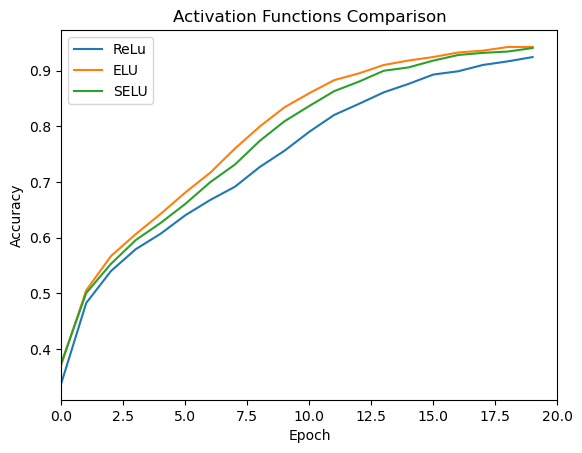

In [ ]:
# Activation functions comparison
plt.plot(history.history["accuracy"])
plt.plot(history_2.history["accuracy"])
plt.plot(history_3.history["accuracy"])
plt.xlim(0, 20)
plt.title("Activation Functions Comparison")
plt.ylabel("Accuracy")
plt.xlabel("Epoch")
plt.legend(["ReLu", "ELU", "SELU"], loc="upper left")
plt.show()

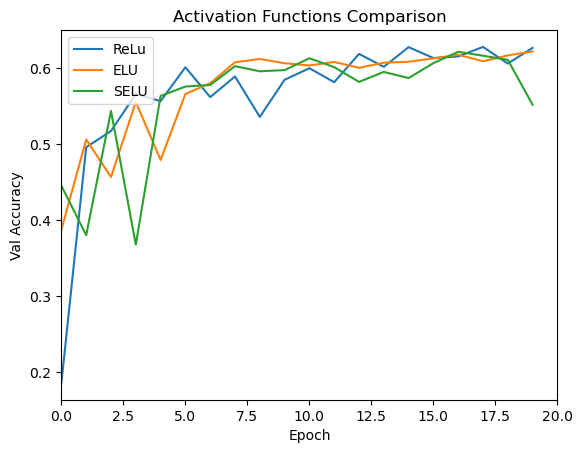

In [ ]:
# Activation functions comparison
plt.plot(history.history["val_accuracy"])
plt.plot(history_2.history["val_accuracy"])
plt.plot(history_3.history["val_accuracy"])
plt.xlim(0, 20)
# plt.ylim(0.6, 0.7)
plt.title("Activation Functions Comparison")
plt.ylabel("Val Accuracy")
plt.xlabel("Epoch")
plt.legend(["ReLu", "ELU", "SELU"], loc="upper left")
plt.show()

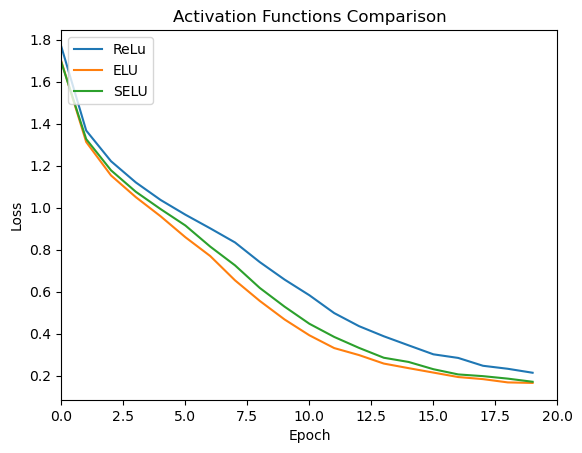

In [ ]:
# Activation functions comparison
plt.plot(history.history["loss"])
plt.plot(history_2.history["loss"])
plt.plot(history_3.history["loss"])
plt.xlim(0, 20)
plt.title("Activation Functions Comparison")
plt.ylabel("Loss")
plt.xlabel("Epoch")
plt.legend(["ReLu", "ELU", "SELU"], loc="upper left")
plt.show()

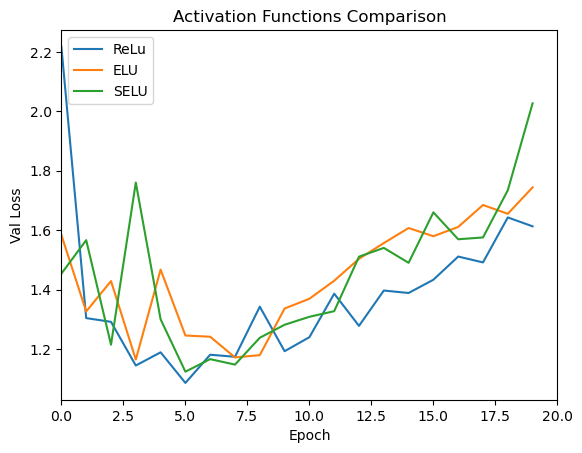

In [ ]:
# Activation functions comparison
plt.plot(history.history["val_loss"])
plt.plot(history_2.history["val_loss"])
plt.plot(history_3.history["val_loss"])
plt.xlim(0, 20)
plt.title("Activation Functions Comparison")
plt.ylabel("Val Loss")
plt.xlabel("Epoch")
plt.legend(["ReLu", "ELU", "SELU"], loc="upper left")
plt.show()

From the graphs and the evaluation of the accuracy of the model, we can see that the SELU function gives the worst results, while the ReLu and ELU functions have similar results. However, we decided to use the ELU activation function as it gave a slightly better accuracy.

### **8. PARAMETER TUNING**

- **Dropout rate:** we will increase the dropout rate of the Model 4 to see if we can obtain less overfitting.  

In [ ]:
# Sequential Keras Model
model_4 = Sequential()

# Input shape of the images
input_shape = (48, 48, 1)

# Layers
model_4.add(
    Conv2D(64, (3, 3), input_shape=input_shape, activation="elu", padding="same")
)
model_4.add(BatchNormalization())
model_4.add(MaxPooling2D(pool_size=(2, 2)))
model_4.add(Dropout(0.3))

model_4.add(Conv2D(128, (3, 3), activation="elu", padding="same"))
model_4.add(Conv2D(128, (3, 3), activation="elu", padding="same"))
model_4.add(BatchNormalization())
model_4.add(MaxPooling2D(pool_size=(2, 2)))
model_4.add(Dropout(0.3))

model_4.add(Conv2D(256, (3, 3), activation="elu", padding="same"))
model_4.add(Conv2D(256, (3, 3), activation="elu", padding="same"))
model_4.add(BatchNormalization())
model_4.add(MaxPooling2D(pool_size=(2, 2)))
model_4.add(Dropout(0.3))

model_4.add(Flatten())
model_4.add(Dense(128, activation="elu"))
model_4.add(BatchNormalization())
model_4.add(Dropout(0.3))

# Output layer with softmax function to normalize the output to a probability distribution
model_4.add(Dense(7, activation="softmax"))

# Compile the Keras Model
model_4.compile(loss="categorical_crossentropy", optimizer="adam", metrics=["accuracy"])

model_4.summary()

C:\Users\cindy\AppData\Roaming\Python\Python39\site-packages\keras\src\layers\convolutional\base_conv.py:107: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential_3"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_15 (Conv2D)              │ (None, 48, 48, 64)     │           640 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_12          │ (None, 48, 48, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_9 (MaxPooling2D)  │ (None, 24, 24, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_12 (Dropout)            │ (None, 24, 24, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_16 (Conv2D)              │ (None, 24, 24, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_17 (Conv2D)              │ (None, 24, 24, 128)    │       147,584 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_13          │ (None, 24, 24, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_10 (MaxPooling2D) │ (None, 12, 12, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_13 (Dropout)            │ (None, 12, 12, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_18 (Conv2D)              │ (None, 12, 12, 256)    │       295,168 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_19 (Conv2D)              │ (None, 12, 12, 256)    │       590,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_14          │ (None, 12, 12, 256)    │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_11 (MaxPooling2D) │ (None, 6, 6, 256)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_14 (Dropout)            │ (None, 6, 6, 256)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_3 (Flatten)             │ (None, 9216)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_6 (Dense)                 │ (None, 128)            │     1,179,776 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_15          │ (None, 128)            │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_15 (Dropout)            │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_7 (Dense)                 │ (None, 7)              │           903 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,290,311 (8.74 MB)

 Trainable params: 2,289,159 (8.73 MB)

 Non-trainable params: 1,152 (4.50 KB)

In [ ]:
# Fit the Keras Model
history_4 = model_4.fit(
    x=x_train,
    y=y_train,
    batch_size=64,
    epochs=20,
    verbose=1,
    validation_data=(x_test, y_test),
)

Epoch 1/20
449/449 ━━━━━━━━━━━━━━━━━━━━ 390s 860ms/step - accuracy: 0.2855 - loss: 2.0255 - val_accuracy: 0.4025 - val_loss: 1.5532
Epoch 2/20
449/449 ━━━━━━━━━━━━━━━━━━━━ 380s 846ms/step - accuracy: 0.4663 - loss: 1.4035 - val_accuracy: 0.5082 - val_loss: 1.2821
Epoch 3/20
449/449 ━━━━━━━━━━━━━━━━━━━━ 400s 890ms/step - accuracy: 0.5393 - loss: 1.2173 - val_accuracy: 0.5261 - val_loss: 1.2554
Epoch 4/20
449/449 ━━━━━━━━━━━━━━━━━━━━ 415s 922ms/step - accuracy: 0.5797 - loss: 1.1116 - val_accuracy: 0.5104 - val_loss: 1.3121
Epoch 5/20
449/449 ━━━━━━━━━━━━━━━━━━━━ 440s 980ms/step - accuracy: 0.6154 - loss: 1.0302 - val_accuracy: 0.5162 - val_loss: 1.3403
Epoch 6/20
449/449 ━━━━━━━━━━━━━━━━━━━━ 472s 1s/step - accuracy: 0.6380 - loss: 0.9656 - val_accuracy: 0.5854 - val_loss: 1.1063
Epoch 7/20
449/449 ━━━━━━━━━━━━━━━━━━━━ 486s 1s/step - accuracy: 0.6607 - loss: 0.9064 - val_accuracy: 0.6057 - val_loss: 1.0832
Epoch 8/20
449/449 ━━━━━━━━━━━━━━━━━━━━ 400s 892ms/step - accuracy: 0.6992 - loss:

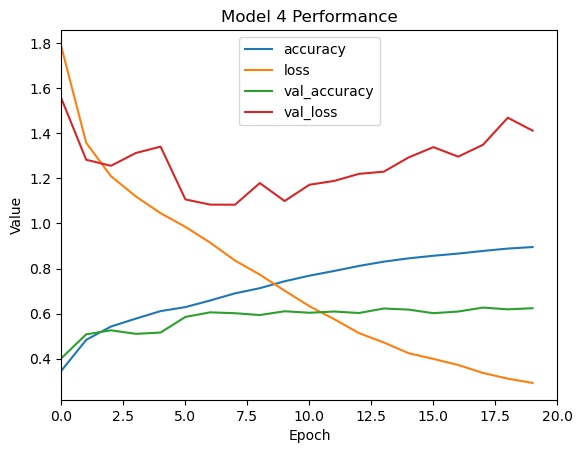

In [37]:
# Model performance plot
perf_4 = pd.DataFrame(history_4.history)
perf_4.plot()
plt.xlim(0, 20)
plt.title("Model 4 Performance")
plt.xlabel("Epoch")
plt.ylabel("Value")
plt.show()

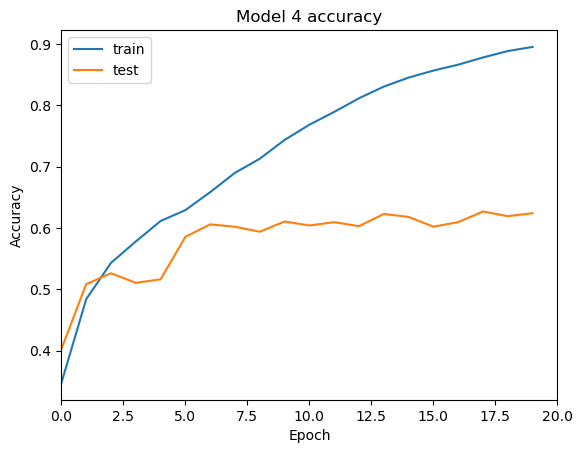

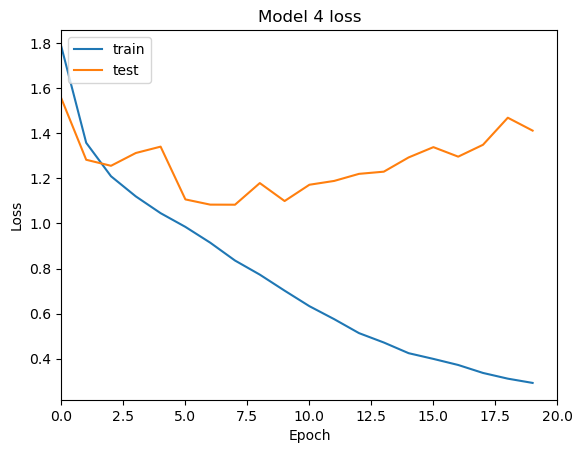

In [ ]:
# Summarize history for accuracy
plt.plot(history_4.history["accuracy"])
plt.plot(history_4.history["val_accuracy"])
plt.xlim(0, 20)
plt.title("Model 4 accuracy")
plt.ylabel("Accuracy")
plt.xlabel("Epoch")
plt.legend(["train", "test"], loc="upper left")
plt.show()

# Summarize history for loss
plt.plot(history_4.history["loss"])
plt.plot(history_4.history["val_loss"])
plt.xlim(0, 20)
plt.title("Model 4 loss")
plt.ylabel("Loss")
plt.xlabel("Epoch")
plt.legend(["train", "test"], loc="upper left")
plt.show()

In [260]:
# Evaluate the model 4
loss, accuracy = model_4.evaluate(x_train, y_train)
print("Accuracy of Model 4: %.2f" % (accuracy * 100))
print("Loss of Model 4: %.2f" % (loss * 100))

val_loss, val_accuracy = model_4.evaluate(x_test, y_test)
print("Validation accuracy of Model 4: %.2f" % (val_accuracy * 100))
print("Validation loss of Model 4: %.2f" % (val_loss * 100))

898/898 ━━━━━━━━━━━━━━━━━━━━ 78s 86ms/step - accuracy: 0.9698 - loss: 0.1117
Accuracy of Model 4: 96.90
Loss of Model 4: 11.20
225/225 ━━━━━━━━━━━━━━━━━━━━ 19s 86ms/step - accuracy: 0.5632 - loss: 1.7302
Validation accuracy of Model 4: 62.40
Validation loss of Model 4: 141.13


We can see that by increasing the dropout rate, the accuracy has increased slightly.

- **Batch size:** now we will increase the batch size to see what happens.

In [ ]:
# Sequential Keras Model
model_5 = Sequential()

# Input shape of the images
input_shape = (48, 48, 1)

# Layers
model_5.add(
    Conv2D(64, (3, 3), input_shape=input_shape, activation="elu", padding="same")
)
model_5.add(BatchNormalization())
model_5.add(MaxPooling2D(pool_size=(2, 2)))
model_5.add(Dropout(0.2))

model_5.add(Conv2D(128, (3, 3), activation="elu", padding="same"))
model_5.add(Conv2D(128, (3, 3), activation="elu", padding="same"))
model_5.add(BatchNormalization())
model_5.add(MaxPooling2D(pool_size=(2, 2)))
model_5.add(Dropout(0.2))

model_5.add(Conv2D(256, (3, 3), activation="elu", padding="same"))
model_5.add(Conv2D(256, (3, 3), activation="elu", padding="same"))
model_5.add(BatchNormalization())
model_5.add(MaxPooling2D(pool_size=(2, 2)))
model_5.add(Dropout(0.2))

model_5.add(Flatten())
model_5.add(Dense(128, activation="elu"))
model_5.add(BatchNormalization())
model_5.add(Dropout(0.2))

# Output layer with softmax function to normalize the output to a probability distribution
model_5.add(Dense(7, activation="softmax"))

# Compile the Keras Model
model_5.compile(loss="categorical_crossentropy", optimizer="adam", metrics=["accuracy"])

model_5.summary()

C:\Users\cindy\AppData\Roaming\Python\Python39\site-packages\keras\src\layers\convolutional\base_conv.py:107: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential_5"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_25 (Conv2D)              │ (None, 48, 48, 64)     │           640 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_20          │ (None, 48, 48, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_15 (MaxPooling2D) │ (None, 24, 24, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_20 (Dropout)            │ (None, 24, 24, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_26 (Conv2D)              │ (None, 24, 24, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_27 (Conv2D)              │ (None, 24, 24, 128)    │       147,584 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_21          │ (None, 24, 24, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_16 (MaxPooling2D) │ (None, 12, 12, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_21 (Dropout)            │ (None, 12, 12, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_28 (Conv2D)              │ (None, 12, 12, 256)    │       295,168 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_29 (Conv2D)              │ (None, 12, 12, 256)    │       590,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_22          │ (None, 12, 12, 256)    │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_17 (MaxPooling2D) │ (None, 6, 6, 256)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_22 (Dropout)            │ (None, 6, 6, 256)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_5 (Flatten)             │ (None, 9216)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_10 (Dense)                │ (None, 128)            │     1,179,776 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_23          │ (None, 128)            │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_23 (Dropout)            │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_11 (Dense)                │ (None, 7)              │           903 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,290,311 (8.74 MB)

 Trainable params: 2,289,159 (8.73 MB)

 Non-trainable params: 1,152 (4.50 KB)

In [ ]:
# Fit the Keras Model
history_5 = model_5.fit(
    x=x_train,
    y=y_train,
    batch_size=128,
    epochs=20,
    verbose=1,
    validation_data=(x_test, y_test),
)

Epoch 1/20
225/225 ━━━━━━━━━━━━━━━━━━━━ 352s 2s/step - accuracy: 0.2966 - loss: 1.9994 - val_accuracy: 0.3532 - val_loss: 1.7675
Epoch 2/20
225/225 ━━━━━━━━━━━━━━━━━━━━ 349s 2s/step - accuracy: 0.4760 - loss: 1.4042 - val_accuracy: 0.4250 - val_loss: 1.5638
Epoch 3/20
225/225 ━━━━━━━━━━━━━━━━━━━━ 348s 2s/step - accuracy: 0.5463 - loss: 1.2132 - val_accuracy: 0.5488 - val_loss: 1.2048
Epoch 4/20
225/225 ━━━━━━━━━━━━━━━━━━━━ 347s 2s/step - accuracy: 0.6000 - loss: 1.0779 - val_accuracy: 0.5692 - val_loss: 1.1642
Epoch 5/20
225/225 ━━━━━━━━━━━━━━━━━━━━ 348s 2s/step - accuracy: 0.6469 - loss: 0.9677 - val_accuracy: 0.5630 - val_loss: 1.1705
Epoch 6/20
225/225 ━━━━━━━━━━━━━━━━━━━━ 347s 2s/step - accuracy: 0.6880 - loss: 0.8576 - val_accuracy: 0.5886 - val_loss: 1.1449
Epoch 7/20
225/225 ━━━━━━━━━━━━━━━━━━━━ 346s 2s/step - accuracy: 0.7313 - loss: 0.7481 - val_accuracy: 0.5814 - val_loss: 1.1721
Epoch 8/20
225/225 ━━━━━━━━━━━━━━━━━━━━ 347s 2s/step - accuracy: 0.7636 - loss: 0.6516 - val_accu

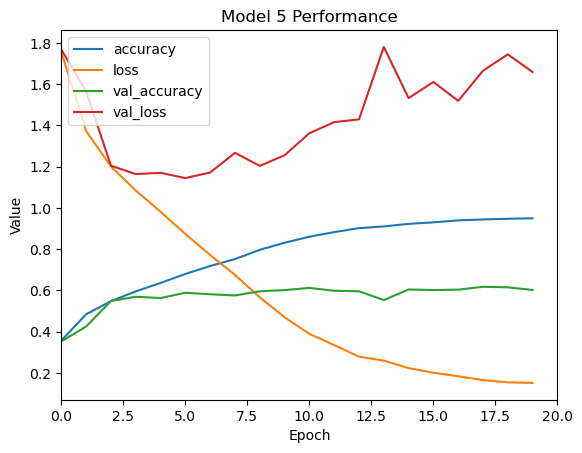

In [47]:
# Model performance plot
perf_5 = pd.DataFrame(history_5.history)
perf_5.plot()
plt.xlim(0, 20)
plt.title("Model 5 Performance")
plt.xlabel("Epoch")
plt.ylabel("Value")
plt.show()

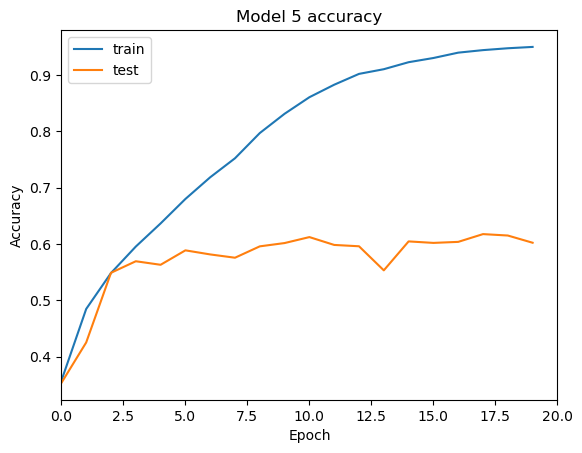

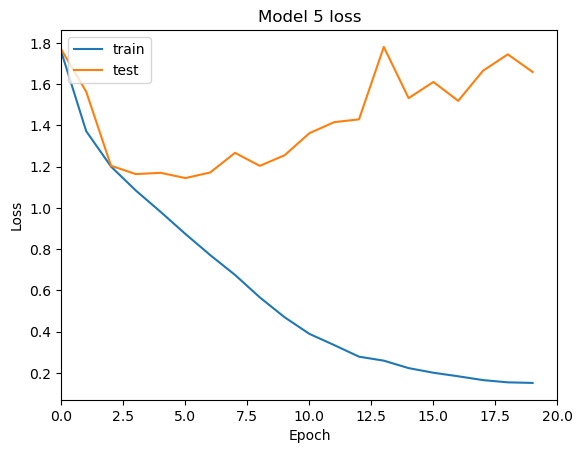

In [ ]:
# Summarize history for accuracy
plt.plot(history_5.history["accuracy"])
plt.plot(history_5.history["val_accuracy"])
plt.xlim(0, 20)
plt.title("Model 5 accuracy")
plt.ylabel("Accuracy")
plt.xlabel("Epoch")
plt.legend(["train", "test"], loc="upper left")
plt.show()

# Summarize history for loss
plt.plot(history_5.history["loss"])
plt.plot(history_5.history["val_loss"])
plt.xlim(0, 20)
plt.title("Model 5 loss")
plt.ylabel("Loss")
plt.xlabel("Epoch")
plt.legend(["train", "test"], loc="upper left")
plt.show()

In [261]:
# Evaluate the model 5
loss, accuracy = model_5.evaluate(x_train, y_train)
print("Accuracy of Model 5: %.2f" % (accuracy * 100))
print("Loss of Model 5: %.2f" % (loss * 100))

val_loss, val_accuracy = model_5.evaluate(x_test, y_test)
print("Validation accuracy of Model 5: %.2f" % (val_accuracy * 100))
print("Validation loss of Model 5: %.2f" % (val_loss * 100))

898/898 ━━━━━━━━━━━━━━━━━━━━ 81s 90ms/step - accuracy: 0.9675 - loss: 0.1062
Accuracy of Model 5: 96.76
Loss of Model 5: 10.71
225/225 ━━━━━━━━━━━━━━━━━━━━ 19s 86ms/step - accuracy: 0.5610 - loss: 1.8600
Validation accuracy of Model 5: 60.21
Validation loss of Model 5: 165.95


By increasing the batch size, the model's accuracy has decreased.  

- **Epochs:** finally, we will increase the number of epochs.

In [ ]:
# Sequential Keras Model
model_6 = Sequential()

# Input shape of the images
input_shape = (48, 48, 1)

# Layers
model_6.add(
    Conv2D(64, (3, 3), input_shape=input_shape, activation="elu", padding="same")
)
model_6.add(BatchNormalization())
model_6.add(MaxPooling2D(pool_size=(2, 2)))
model_6.add(Dropout(0.25))

model_6.add(Conv2D(128, (3, 3), activation="elu", padding="same"))
model_6.add(Conv2D(128, (3, 3), activation="elu", padding="same"))
model_6.add(BatchNormalization())
model_6.add(MaxPooling2D(pool_size=(2, 2)))
model_6.add(Dropout(0.25))

model_6.add(Conv2D(256, (3, 3), activation="elu", padding="same"))
model_6.add(Conv2D(256, (3, 3), activation="elu", padding="same"))
model_6.add(BatchNormalization())
model_6.add(MaxPooling2D(pool_size=(2, 2)))
model_6.add(Dropout(0.25))

model_6.add(Flatten())
model_6.add(Dense(128, activation="elu"))
model_6.add(BatchNormalization())
model_6.add(Dropout(0.25))

# Output layer with softmax function to normalize the output to a probability distribution
model_6.add(Dense(7, activation="softmax"))

# Compile the Keras Model
model_6.compile(loss="categorical_crossentropy", optimizer="adam", metrics=["accuracy"])

model_6.summary()

C:\Users\cindy\AppData\Roaming\Python\Python39\site-packages\keras\src\layers\convolutional\base_conv.py:107: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential_6"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_30 (Conv2D)              │ (None, 48, 48, 64)     │           640 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_24          │ (None, 48, 48, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_18 (MaxPooling2D) │ (None, 24, 24, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_24 (Dropout)            │ (None, 24, 24, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_31 (Conv2D)              │ (None, 24, 24, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_32 (Conv2D)              │ (None, 24, 24, 128)    │       147,584 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_25          │ (None, 24, 24, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_19 (MaxPooling2D) │ (None, 12, 12, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_25 (Dropout)            │ (None, 12, 12, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_33 (Conv2D)              │ (None, 12, 12, 256)    │       295,168 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_34 (Conv2D)              │ (None, 12, 12, 256)    │       590,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_26          │ (None, 12, 12, 256)    │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_20 (MaxPooling2D) │ (None, 6, 6, 256)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_26 (Dropout)            │ (None, 6, 6, 256)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_6 (Flatten)             │ (None, 9216)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_12 (Dense)                │ (None, 128)            │     1,179,776 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_27          │ (None, 128)            │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_27 (Dropout)            │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_13 (Dense)                │ (None, 7)              │           903 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,290,311 (8.74 MB)

 Trainable params: 2,289,159 (8.73 MB)

 Non-trainable params: 1,152 (4.50 KB)

In [ ]:
# Fit the Keras Model
history_6 = model_6.fit(
    x=x_train,
    y=y_train,
    batch_size=64,
    epochs=30,
    verbose=1,
    validation_data=(x_test, y_test),
)

Epoch 1/30
449/449 ━━━━━━━━━━━━━━━━━━━━ 395s 871ms/step - accuracy: 0.3132 - loss: 1.9681 - val_accuracy: 0.3816 - val_loss: 1.8210
Epoch 2/30
449/449 ━━━━━━━━━━━━━━━━━━━━ 350s 778ms/step - accuracy: 0.4918 - loss: 1.3515 - val_accuracy: 0.5192 - val_loss: 1.2775
Epoch 3/30
449/449 ━━━━━━━━━━━━━━━━━━━━ 343s 764ms/step - accuracy: 0.5596 - loss: 1.1748 - val_accuracy: 0.5245 - val_loss: 1.2556
Epoch 4/30
449/449 ━━━━━━━━━━━━━━━━━━━━ 343s 765ms/step - accuracy: 0.5898 - loss: 1.0838 - val_accuracy: 0.5600 - val_loss: 1.1886
Epoch 5/30
449/449 ━━━━━━━━━━━━━━━━━━━━ 345s 767ms/step - accuracy: 0.6297 - loss: 1.0007 - val_accuracy: 0.5982 - val_loss: 1.0787
Epoch 6/30
449/449 ━━━━━━━━━━━━━━━━━━━━ 349s 777ms/step - accuracy: 0.6601 - loss: 0.9122 - val_accuracy: 0.5787 - val_loss: 1.1287
Epoch 7/30
449/449 ━━━━━━━━━━━━━━━━━━━━ 343s 764ms/step - accuracy: 0.6963 - loss: 0.8216 - val_accuracy: 0.5847 - val_loss: 1.1080
Epoch 8/30
449/449 ━━━━━━━━━━━━━━━━━━━━ 370s 824ms/step - accuracy: 0.7318 -

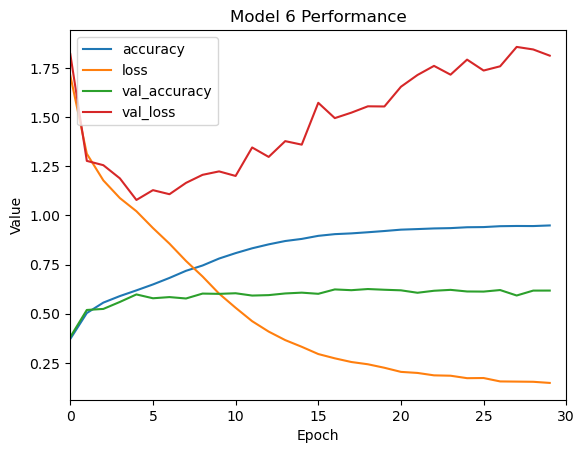

In [53]:
# Model performance plot
perf_6 = pd.DataFrame(history_6.history)
perf_6.plot()
plt.xlim(0, 30)
plt.title("Model 6 Performance")
plt.xlabel("Epoch")
plt.ylabel("Value")
plt.show()

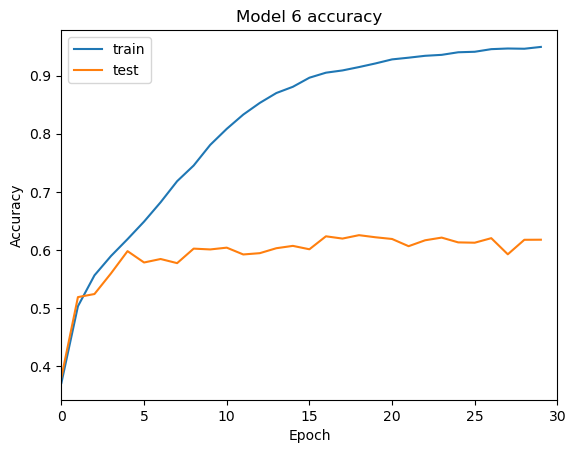

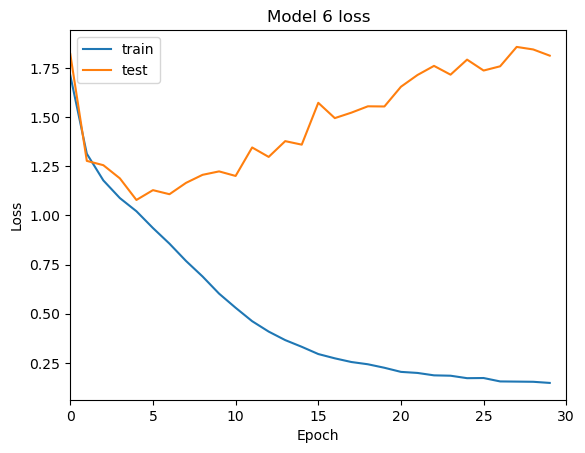

In [ ]:
# Summarize history for accuracy
plt.plot(history_6.history["accuracy"])
plt.plot(history_6.history["val_accuracy"])
plt.xlim(0, 30)
plt.title("Model 6 accuracy")
plt.ylabel("Accuracy")
plt.xlabel("Epoch")
plt.legend(["train", "test"], loc="upper left")
plt.show()

# Summarize history for loss
plt.plot(history_6.history["loss"])
plt.plot(history_6.history["val_loss"])
plt.xlim(0, 30)
plt.title("Model 6 loss")
plt.ylabel("Loss")
plt.xlabel("Epoch")
plt.legend(["train", "test"], loc="upper left")
plt.show()

In [262]:
# Evaluate the model 6
loss, accuracy = model_6.evaluate(x_train, y_train)
print("Accuracy of Model 6: %.2f" % (accuracy * 100))
print("Loss of Model 6: %.2f" % (loss * 100))

val_loss, val_accuracy = model_6.evaluate(x_test, y_test)
print("Validation accuracy of Model 6: %.2f" % (val_accuracy * 100))
print("Validation loss of Model 6: %.2f" % (val_loss * 100))

898/898 ━━━━━━━━━━━━━━━━━━━━ 77s 85ms/step - accuracy: 0.9943 - loss: 0.0237
Accuracy of Model 6: 99.41
Loss of Model 6: 2.42
225/225 ━━━━━━━━━━━━━━━━━━━━ 19s 85ms/step - accuracy: 0.5834 - loss: 2.0112
Validation accuracy of Model 6: 61.79
Validation loss of Model 6: 181.28


It must also be taken into account that other hyperparameters like number of layers, learning rate, optimizers, etc. can also be tuned to further improve the model.

---

### **9. VALIDATION**  

Finally, we evaluated the trained model's performance using the test dataset.  

Using the ``classification_report`` we calculated metrics such as the precision, recall, F1-score to assess its effectiveness.  

Additionally, we calculated the $R^2$ coefficient and plotted the confusion matrix using the ``confusion_matrix`` function.  

- **Classification report:**  

    - Accuracy: proportion of correct predictions.
    - Precision: proportion of true positive predictions out of all positive predictions.
    - Recall: proportion of true positive predictions out of all actual positives.
    - F1: balance between precision and recall.
    - Support: number of occurrences of each class in the dataset.

In [ ]:
from sklearn.metrics import classification_report

# Convert one-hot encoded y_test back to integers
y_test_int = np.argmax(y_test, axis=1)

# Make predictions
y_pred_1 = model.predict(x_test)
y_pred_2 = model_2.predict(x_test)
y_pred_3 = model_3.predict(x_test)
y_pred_4 = model_4.predict(x_test)
y_pred_5 = model_5.predict(x_test)
y_pred_6 = model_6.predict(x_test)

# Convert one-hot encoded y_pred back to integers
y_pred_1_int = np.argmax(y_pred_1, axis=1)
y_pred_2_int = np.argmax(y_pred_2, axis=1)
y_pred_3_int = np.argmax(y_pred_3, axis=1)
y_pred_4_int = np.argmax(y_pred_4, axis=1)
y_pred_5_int = np.argmax(y_pred_5, axis=1)
y_pred_6_int = np.argmax(y_pred_6, axis=1)

225/225 ━━━━━━━━━━━━━━━━━━━━ 19s 81ms/step
225/225 ━━━━━━━━━━━━━━━━━━━━ 18s 79ms/step
225/225 ━━━━━━━━━━━━━━━━━━━━ 20s 88ms/step
225/225 ━━━━━━━━━━━━━━━━━━━━ 29s 129ms/step
225/225 ━━━━━━━━━━━━━━━━━━━━ 19s 84ms/step
225/225 ━━━━━━━━━━━━━━━━━━━━ 21s 93ms/step


In [ ]:
# Generate classification report
print(
    "Classification report Model 1:\n", classification_report(y_test_int, y_pred_1_int)
)
print(
    "Classification report Model 2:\n", classification_report(y_test_int, y_pred_2_int)
)
print(
    "Classification report Model 3:\n", classification_report(y_test_int, y_pred_3_int)
)
print(
    "Classification report Model 4:\n", classification_report(y_test_int, y_pred_4_int)
)
print(
    "Classification report Model 5:\n", classification_report(y_test_int, y_pred_5_int)
)
print(
    "Classification report Model 6:\n", classification_report(y_test_int, y_pred_6_int)
)

Classification report Model 1:
               precision    recall  f1-score   support

           0       0.55      0.56      0.55       958
           1       0.90      0.58      0.70       111
           2       0.46      0.52      0.49      1024
           3       0.82      0.82      0.82      1774
           4       0.55      0.62      0.58      1233
           5       0.54      0.43      0.48      1247
           6       0.75      0.74      0.75       831

    accuracy                           0.63      7178
   macro avg       0.65      0.61      0.62      7178
weighted avg       0.63      0.63      0.63      7178

Classification report Model 2:
               precision    recall  f1-score   support

           0       0.52      0.55      0.53       958
           1       0.78      0.54      0.64       111
           2       0.52      0.42      0.47      1024
           3       0.78      0.85      0.81      1774
           4       0.54      0.59      0.57      1233
           5  

Looking at the classification reports, we can see that Model 1 and Model 4 are the best ones.

- **Confusion Matrix**

In [75]:
from sklearn.metrics import confusion_matrix

emotions_labels = ["angry", "disgust", "fear", "happy", "neutral", "sad", "surprise"]

# Calculate confusion matrices
cm_1 = confusion_matrix(y_test_int, y_pred_1_int)
cm_2 = confusion_matrix(y_test_int, y_pred_2_int)
cm_3 = confusion_matrix(y_test_int, y_pred_3_int)
cm_4 = confusion_matrix(y_test_int, y_pred_4_int)
cm_5 = confusion_matrix(y_test_int, y_pred_5_int)
cm_6 = confusion_matrix(y_test_int, y_pred_6_int)

Text(0.5, 1.0, 'Confusion Matrix Model 1')

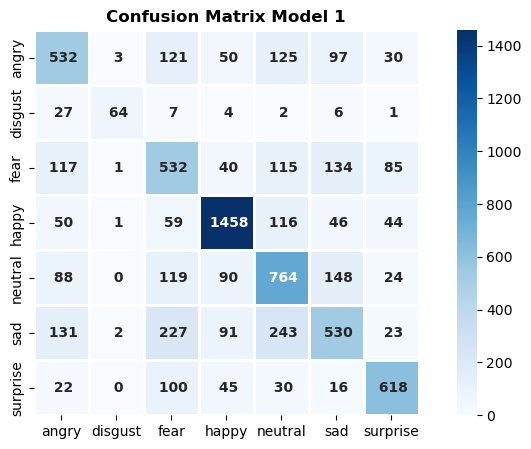

In [ ]:
# Confusion matrix 1
fig, ax = plt.subplots(figsize=(10, 5))
sns.heatmap(
    cm_1,
    cmap="Blues",
    annot=True,
    fmt=" ",
    square=True,
    annot_kws={"fontweight": "bold"},
    linewidths=1.0,
    cbar=True,
    xticklabels=emotions_labels,
    yticklabels=emotions_labels,
    ax=ax,
)

ax.set_title("Confusion Matrix Model 1", fontsize=12, fontweight="bold")

Text(0.5, 1.0, 'Confusion Matrix Model 2')

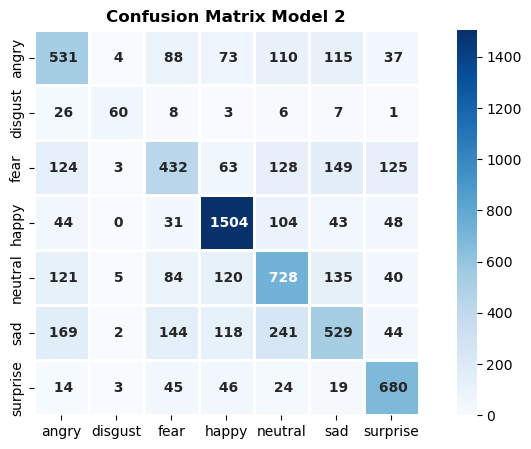

In [ ]:
# Confusion matrix 2
fig, ax = plt.subplots(figsize=(10, 5))
sns.heatmap(
    cm_2,
    cmap="Blues",
    annot=True,
    fmt=" ",
    square=True,
    annot_kws={"fontweight": "bold"},
    linewidths=1.0,
    cbar=True,
    xticklabels=emotions_labels,
    yticklabels=emotions_labels,
    ax=ax,
)

ax.set_title("Confusion Matrix Model 2", fontsize=12, fontweight="bold")

Text(0.5, 1.0, 'Confusion Matrix Model 3')

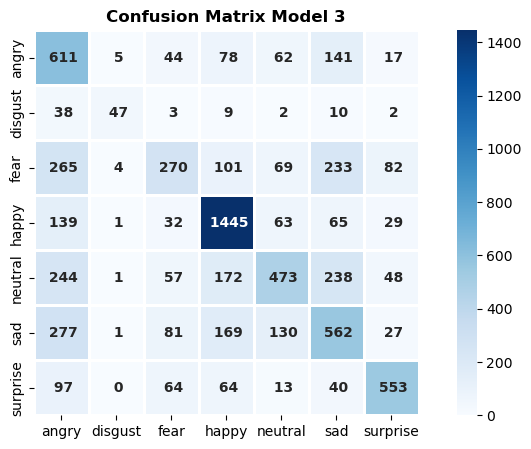

In [ ]:
# Confusion matrix 3
fig, ax = plt.subplots(figsize=(10, 5))
sns.heatmap(
    cm_3,
    cmap="Blues",
    annot=True,
    fmt=" ",
    square=True,
    annot_kws={"fontweight": "bold"},
    linewidths=1.0,
    cbar=True,
    xticklabels=emotions_labels,
    yticklabels=emotions_labels,
    ax=ax,
)

ax.set_title("Confusion Matrix Model 3", fontsize=12, fontweight="bold")

Text(0.5, 1.0, 'Confusion Matrix Model 4')

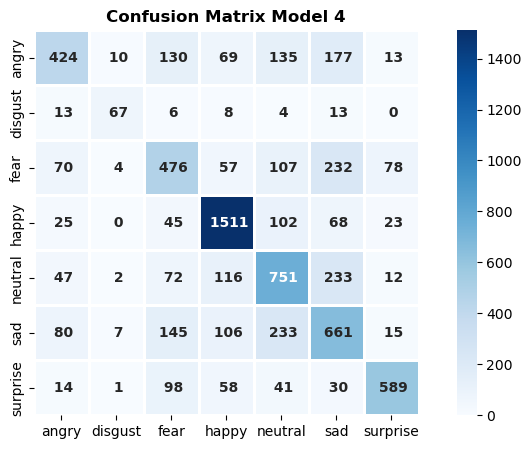

In [ ]:
# Confusion matrix 4
fig, ax = plt.subplots(figsize=(10, 5))
sns.heatmap(
    cm_4,
    cmap="Blues",
    annot=True,
    fmt=" ",
    square=True,
    annot_kws={"fontweight": "bold"},
    linewidths=1.0,
    cbar=True,
    xticklabels=emotions_labels,
    yticklabels=emotions_labels,
    ax=ax,
)

ax.set_title("Confusion Matrix Model 4", fontsize=12, fontweight="bold")

Text(0.5, 1.0, 'Confusion Matrix Model 5')

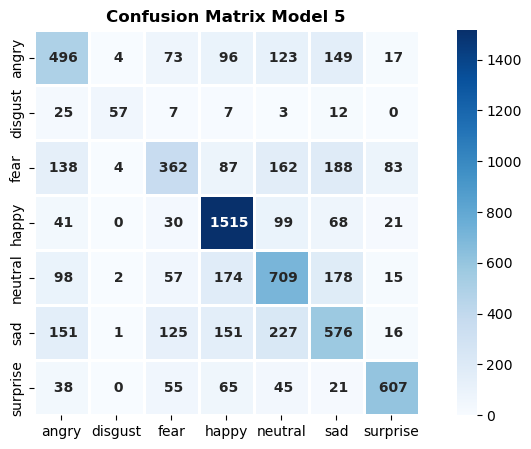

In [ ]:
# Confusion matrix 5
fig, ax = plt.subplots(figsize=(10, 5))
sns.heatmap(
    cm_5,
    cmap="Blues",
    annot=True,
    fmt=" ",
    square=True,
    annot_kws={"fontweight": "bold"},
    linewidths=1.0,
    cbar=True,
    xticklabels=emotions_labels,
    yticklabels=emotions_labels,
    ax=ax,
)

ax.set_title("Confusion Matrix Model 5", fontsize=12, fontweight="bold")

Text(0.5, 1.0, 'Confusion Matrix Model 6')

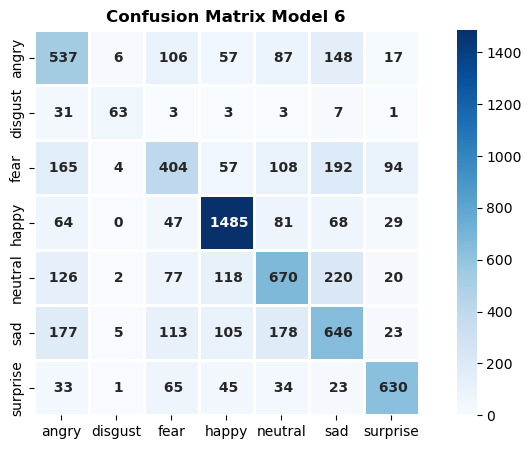

In [ ]:
# Confusion matrix 6
fig, ax = plt.subplots(figsize=(10, 5))
sns.heatmap(
    cm_6,
    cmap="Blues",
    annot=True,
    fmt=" ",
    square=True,
    annot_kws={"fontweight": "bold"},
    linewidths=1.0,
    cbar=True,
    xticklabels=emotions_labels,
    yticklabels=emotions_labels,
    ax=ax,
)

ax.set_title("Confusion Matrix Model 6", fontsize=12, fontweight="bold")

- **$R^2$ score** 

In [ ]:
from sklearn.metrics import r2_score

# Calculate R2 score
r2_1 = r2_score(y_test, y_pred_1)
r2_2 = r2_score(y_test, y_pred_2)
r2_3 = r2_score(y_test, y_pred_3)
r2_4 = r2_score(y_test, y_pred_4)
r2_5 = r2_score(y_test, y_pred_5)
r2_6 = r2_score(y_test, y_pred_6)

In [251]:
# Print R2 scores
print("Model 1 R2 score:", r2_1)
print("Model 2 R2 score:", r2_2)
print("Model 3 R2 score:", r2_3)
print("Model 4 R2 score:", r2_4)
print("Model 5 R2 score:", r2_5)
print("Model 6 R2 score:", r2_6)

Model 1 R2 score: 0.3158690134440336
Model 2 R2 score: 0.2986889386380901
Model 3 R2 score: 0.17301587150983336
Model 4 R2 score: 0.3353823222800158
Model 5 R2 score: 0.2813265159557398
Model 6 R2 score: 0.28245419341693795


Models 1 and 4 have the highest $R^2$ scores, meaning that these are the two models that fits the data best and are able to make accurate predictions. However, the values are still not close  to 1.

---

### **10. PREDICTIONS**  

Finally, we will see how the model makes guesses about new images. First, we defined a function to plot the probability of each emotion. Then, a secod function that loads the input image, processes it and predicts the emotions using the Model 4 and finally, that it displays the image along with a graph with the probability of each emotion.

In [ ]:
# Define function to plot emotion prediction graph
def emotion_prediction(emotions):
    """Function that plots the probability of an emotion"""

    emotions_labels = [
        "angry",
        "disgust",
        "fear",
        "happy",
        "neutral",
        "sad",
        "surprise",
    ]
    y_pos = np.arange(len(emotions_labels))

    # Convert to percentages
    emotions_percentages = [emotion * 100 for emotion in emotions]

    # Plot the bar graph
    colors = [
        "#D95F02",
        "#66A61E",
        "#1B9E77",
        "#E6AB02",
        "#666666",
        "#7570B3",
        "#E7298A",
    ]
    plt.bar(y_pos, emotions_percentages, align="center", alpha=0.9, color=colors)
    plt.ylim(0, 100)
    plt.tick_params(axis="x", which="both", pad=10, width=4, length=10)
    plt.xticks(y_pos, emotions_labels)
    plt.title("Emotion Prediction")
    plt.ylabel("Percentage")
    plt.show()

In [ ]:
from keras.preprocessing import image


# Define function that loads an image and predicts the emotion
def predict_image(picture):
    """Function that loads an image, processes it, predicts the emotion using
    a model and displays the image along with a graph with the probability of
    an emotion"""

    # Load image in grayscale and resize
    img = image.load_img(picture, color_mode="grayscale", target_size=(48, 48))
    show_img = image.load_img(picture, color_mode="grayscale", target_size=(200, 200))

    # Convert image to numpy and expand it to match the input size
    x = image.img_to_array(img)
    x = np.expand_dims(x, axis=0)

    # Normalize
    x /= 255

    plt.gray()
    plt.imshow(show_img)
    plt.show()

    # Make prediction using the model
    pred = model_4.predict(x)

    # Plot the probability graph
    emotion_prediction(pred[0])

    # Reshape the image to display it
    x = np.array(x, "float32")
    x = x.reshape([48, 48])
    # Find the index of the emotion with the highest probability
    j = 0.000000000000000000001
    a = pred[0]
    for k in range(0, len(a)):
        if a[k] > j:
            j = a[k]
            ind = k

    print("Emotion Predicted:", emotions_labels[ind])

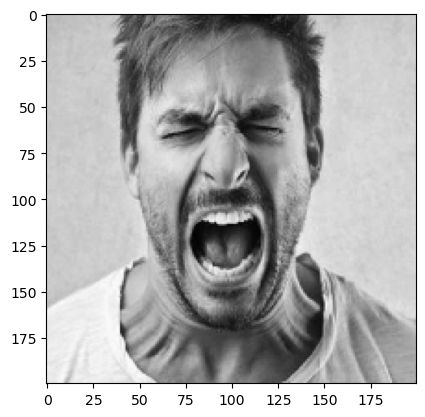

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 269ms/step


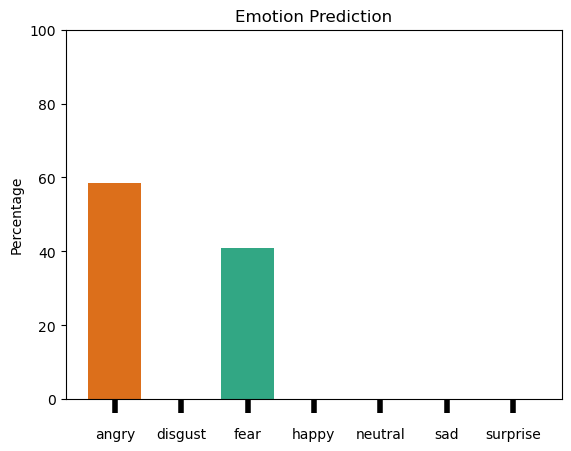

Emotion Predicted: angry


In [33]:
# Example
predict_image("predict\\man_1.jpg")

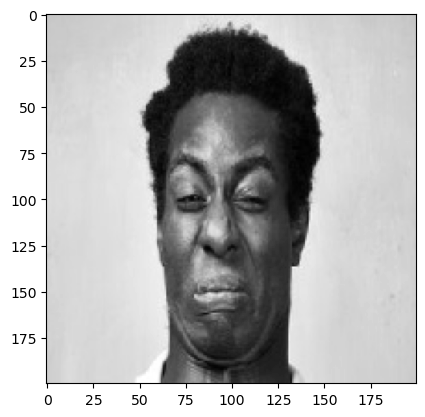

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 28ms/step


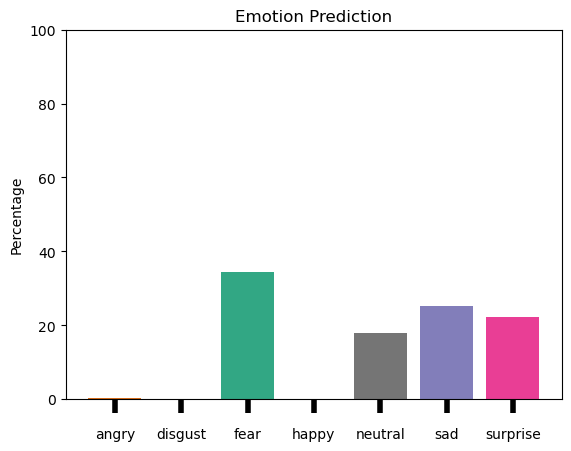

Emotion Predicted: fear


In [35]:
# Example
predict_image("predict\\man_2.jpg")

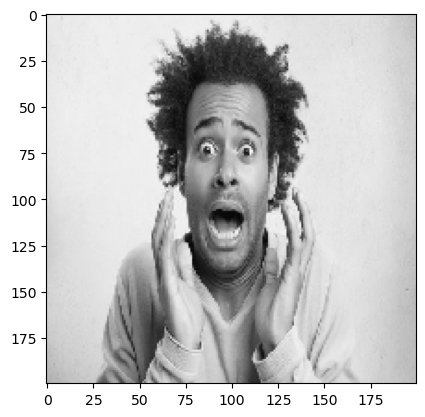

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 35ms/step


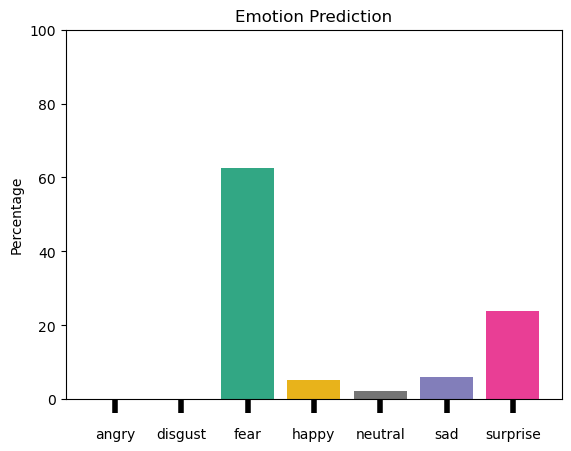

Emotion Predicted: fear


In [36]:
# Example
predict_image("predict\\man_3.jpg")

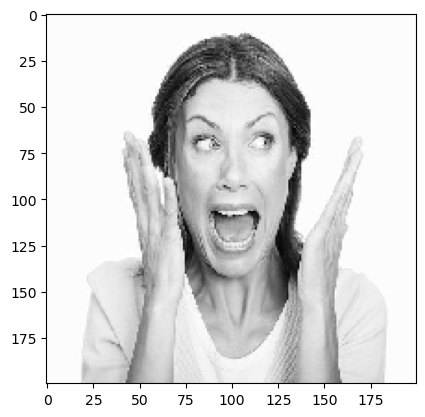

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 31ms/step


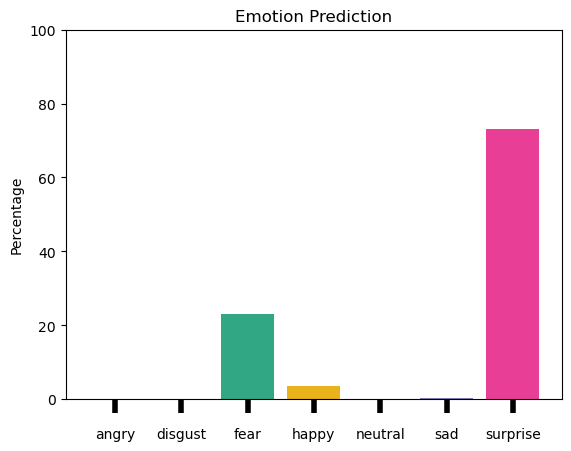

Emotion Predicted: surprise


In [37]:
# Example
predict_image("predict\\woman_1.jpg")

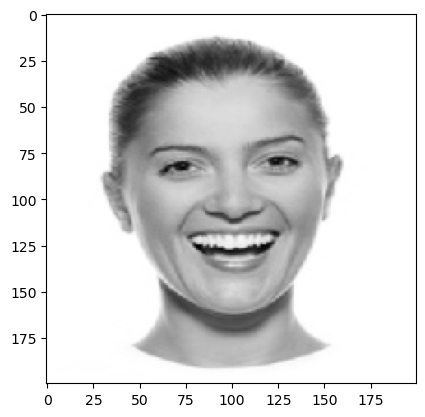

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 82ms/step


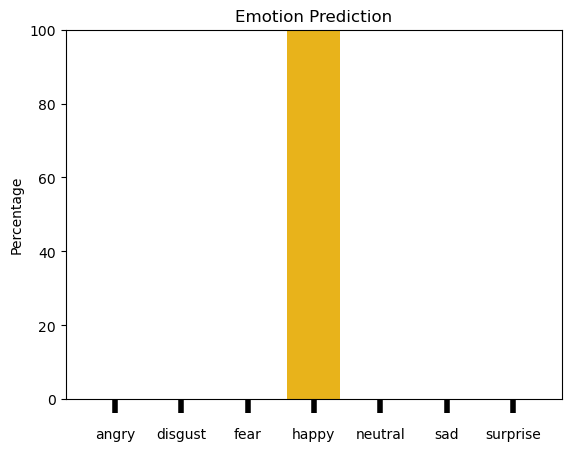

Emotion Predicted: happy


In [38]:
# Example
predict_image("predict\\woman_2.png")

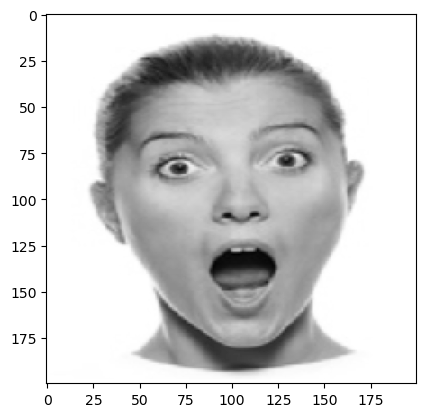

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 26ms/step


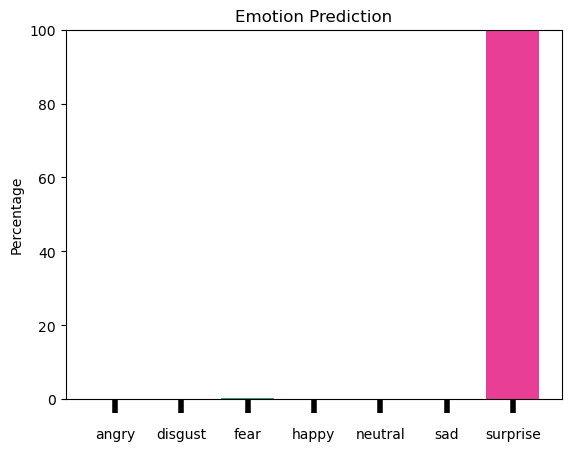

Emotion Predicted: surprise


In [39]:
# Example
predict_image("predict\\woman_3.png")

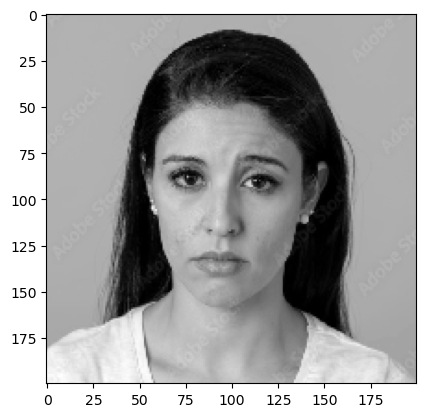

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 18ms/step


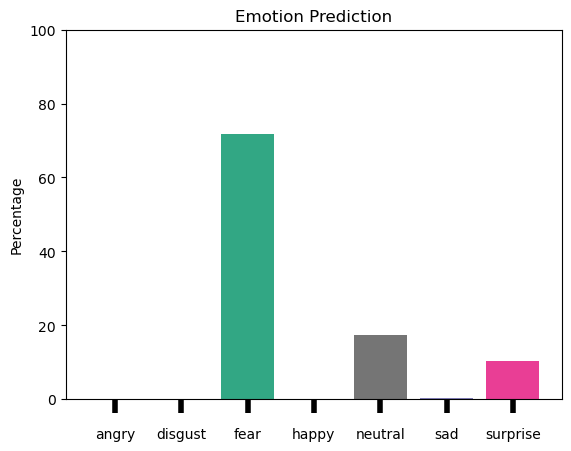

Emotion Predicted: fear


In [40]:
# Example
predict_image("predict\\woman_4.jpg")

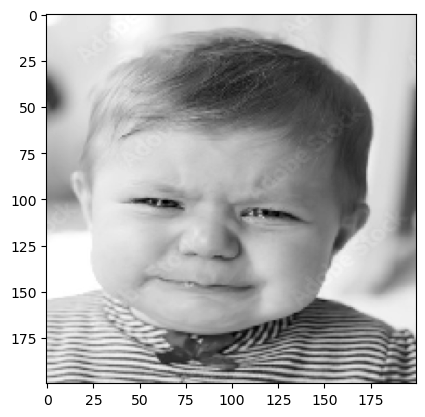

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 32ms/step


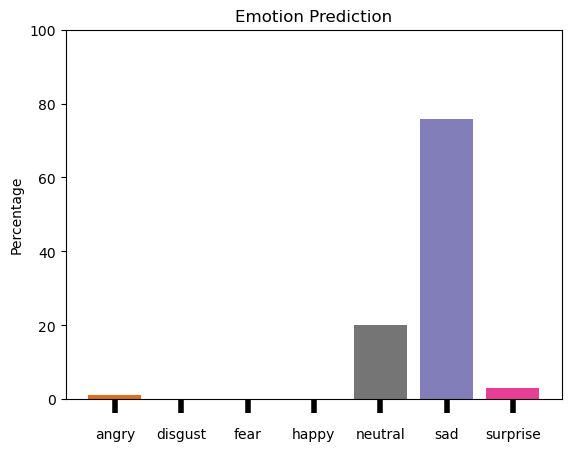

Emotion Predicted: sad


In [41]:
# Example
predict_image("predict\\baby_1.jpg")

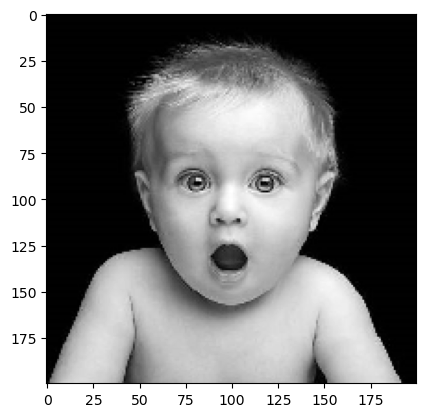

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 30ms/step


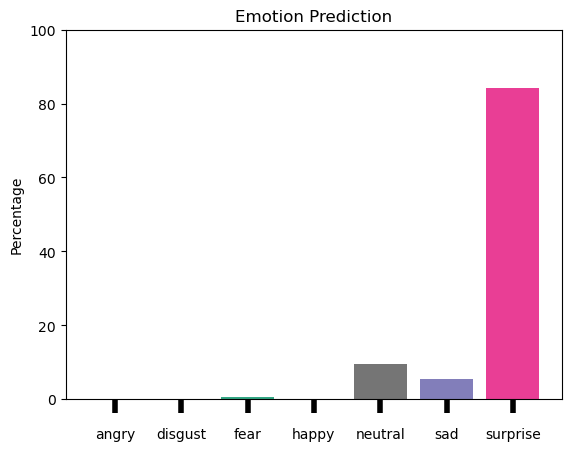

Emotion Predicted: surprise


In [42]:
# Example
predict_image("predict\\baby_2.jpg")

---

### **11. ETHICAL ASPECTS**  

The use of facial emotion recognition technology, or facial emotion AI, is experiencing significant growth. And it is becoming increasingly useful in a variety of industries. However, as with any new technology, especially in healthcare, it is important to consider the ethical and responsible use of facial emotion recognition tools [[4]](https://www.morphcast.com/blog/ethic-and-responsible-use-of-face-emotion-recognition/) [[5]](https://link.springer.com/article/10.1007/s43681-023-00307-3).  

##### **11.1 Privacy**

Privacy is one of the main concerns associated with facial emotion recognition. The technology relies on the collection and analysis of images and facial data. This raises questions about who has access to this information and what use they make of it. It is therefore crucial to implement strict privacy policies and secure data protection measures to protect individuals' personal information.    

##### **11.2 Bias** 

Another concern is the possibility of bias in the algorithm. If the data used to train these algorithms is not diverse, it may lead to inaccurate or biased results. To avoid this risk, we have ensured that our database is sufficiently large, has a diversity of emotions, and also includes a wide variety of images spanning different ages and races. However as mentioned before, there are a few images for the *disgust* emotion which could lead to bias. 

##### **11.3 Responsible use**

Such a technology could be used to monitor or manipulate a person. Therefore, it’s important to provide all necessary information to improve the understanding and ethical use of the technology, both for doctors and for the patients who will be subjected to it. Thus, it’s important to ask for consent from the patient before its use.
 

---

### **12. FUTURE IMPROVMENTS**  

Regarding the improvement of the model, parameters such as the batch size, learning rate, optimizers, etc. could be tuned to further improve the accuracy.   

In relation to the applications, one of the functionalities that we proposed at the beginning was to implement the model in consultations. This would imply the incorporation of a Webcam that would allow to take photos instantly and classify emotions instantly.  

Additionally, a new target patient could be newborns. In the field of neonatology, it would be interesting to study how external stimuli, such as changes in light, affect their emotional development, which would make it possible to measure the level of stress to which they are sometimes subjected in the NICU and thus improve the environmental conditions. To this end, it would be essential to reinforce privacy and security measures, ensuring that it is the parents who authorize the use of the webcam on their child.


---

### **13. CONCLUSIONS**  

In conclusion, this technology has the potential to improve the diagnosis and psychological understanding in patients undergoing pharmacological treatments or in complex pediatric cases where the study of emotional state or pain level is difficult. To achieve this, it is essential that facial emotion recognition technology is used ethically and responsibly. 

---

### **14. REFERENCES**  

[1] Beltramin, A. (2023, January 24). Face Emotion Recognition in healthcare – How can we use it in 2023? MorphCast. https://www.morphcast.com/blog/face-emotion-recognition-in-healthcare-how-can-it-be-used/   

[2] Mini project. (2023, January 10). Kaggle.com; Kaggle. https://www.kaggle.com/code/ramubathula/mini-project/input   

[3] OpenCV - classification of emotions. (2021, December 6). Kaggle.com; Kaggle. https://www.kaggle.com/code/juniorbueno/opencv-classification-of-emotions/notebook   

[4] Bargagni, S. (2023, January 25). Ethic and responsible use of face emotion recognition in 2023. MorphCast. https://www.morphcast.com/blog/ethic-and-responsible-use-of-face-emotion-recognition/   

[5] Katirai, A. (2023). Ethical considerations in emotion recognition technologies: a review of the literature. AI and Ethics. https://doi.org/10.1007/s43681-023-00307-3 